# Word2Vec Implementation: Skip-gram and CBOW Models on WikiText-2

This project implements and compares two popular Word2Vec architectures — **Skip-gram** and **CBOW** — from scratch using PyTorch. The models are trained on the WikiText-2 dataset, and their learned word embeddings are evaluated and compared through similarity analysis and t-SNE visualizations.

## Project Structure
1. **Data Loading** — Load WikiText-2 from Hugging Face
2. **Text Preprocessing** — Tokenization, vocabulary building, sample generation, DataLoaders
3. **Model Implementation & Training** — Skip-gram and CBOW neural networks, training loops, loss curves
4. **Model Comparison & Analysis** — Similar-word retrieval, cosine similarity, t-SNE plots, difference analysis


## Import All Libraries

In [ ]:
import re
import torch
import numpy as np
import torch.nn as nn
from tqdm import tqdm
import seaborn as sns
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn.functional as F
from datasets import load_dataset
from sklearn.manifold import TSNE
from matplotlib.patches import Ellipse
from collections import Counter, defaultdict
from torch.utils.data import Dataset, DataLoader

## 1. Data Loading

Load the **WikiText-2** dataset from the Hugging Face `datasets` library and export each split (train, validation, test) to plain text files for downstream processing.

In [ ]:
dataset = load_dataset('wikitext', 'wikitext-2-raw-v1')
print("WikiText-2 Dataset:")

for split_name, split_data in dataset.items():
    print(f"{split_name}: {len(split_data)} samples")

for split_name, split_data in dataset.items():
    filename = f"{split_name}.txt"
    with open(filename, "w", encoding="utf-8") as f:
        for item in split_data["text"]:
            f.write(item + "\n")


WikiText-2 Dataset:
test: 4358 samples
train: 36718 samples
validation: 3760 samples


## 2. Text Preprocessing

Implement text preprocessing (lowercasing and punctuation removal), vocabulary building with minimum frequency filtering, CBOW and Skip-gram sample generation, custom PyTorch `Dataset` classes, and `DataLoader`s with custom collate functions for batch processing.

In [ ]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    tokens = text.split()
    return tokens

test_text = "Hello World! This is a TEST sentence, with 123 numbers."
result = preprocess_text(test_text)
print("First Section - Preprocessing Test:")
print(f"Input: {test_text}")
print(f"Output: {result}")

def build_vocabulary(texts, min_freq=2, unk_token="<UNK>"):
    word_freq = Counter()
    for text in texts:
        tokens = preprocess_text(text)
        word_freq.update(tokens)

    filtered_words = [word for word, count in word_freq.items() if count >= min_freq]
    vocab = [unk_token] + filtered_words
    word2idx = {}
    idx2word = {}

    for idx, word in enumerate(vocab):
        word2idx[word] = idx
        idx2word[idx] = word

    print(f"Total word count: {len(word_freq)}")
    print(f"Number of words after filtering (min_freq={min_freq}): {len(filtered_words)}")
    print(f"Final vocabulary size: {len(vocab)}")

    return word2idx, idx2word, word_freq

test_texts = ["the cat sat on the mat", "the dog sat on the log", "cats and dogs"]
word2idx, idx2word, word_freq = build_vocabulary(test_texts, min_freq=2)
print("\nSecond Section - Vocabulary Building Test:")
print("Vocabulary:", word2idx)
print("Word frequency:", dict(word_freq))
print()


def create_cbow_samples(tokens, word2idx, window_size=2):
    samples = []
    vocab_size = len(word2idx)
    unk_idx = word2idx.get("<UNK>", 0)

    for i in range(window_size, len(tokens) - window_size):
        context_words = []
        for j in range(-window_size, window_size + 1):
            if j != 0:
                context_words.append(tokens[i + j])

        target_word = tokens[i]
        context_indices = [word2idx.get(word, unk_idx) for word in context_words]
        target_idx = word2idx.get(target_word, unk_idx)
        samples.append((context_indices, target_idx))

    return samples

def create_skipgram_samples(tokens, word2idx, window_size=2):
    samples = []
    vocab_size = len(word2idx)
    unk_idx = word2idx.get("<UNK>", 0)

    for i in range(window_size, len(tokens) - window_size):
        target_word = tokens[i]
        target_idx = word2idx.get(target_word, unk_idx)

        for j in range(-window_size, window_size + 1):
            if j != 0:
                context_word = tokens[i + j]
                context_idx = word2idx.get(context_word, unk_idx)
                samples.append((target_idx, context_idx))

    return samples

test_tokens = preprocess_text("the cat sat on the mat")
print("\nThird Section - Test generating training samples:")
print(f"Tokens: {test_tokens}")

cbow_samples = create_cbow_samples(test_tokens, word2idx, window_size=1)
skipgram_samples = create_skipgram_samples(test_tokens, word2idx, window_size=1)

print(f"CBOW examples (window_size=1): {cbow_samples}")
print(f"Skip-gram examples (window_size=1): {skipgram_samples}")
print()


class Word2VecDataset(Dataset):
    def __init__(self, texts, word2idx, method='cbow', window_size=2):
        self.word2idx = word2idx
        self.method = method
        self.window_size = window_size
        self.samples = []

        for text in texts:
            tokens = preprocess_text(text)
            if len(tokens) > 2 * window_size:
                if method == 'cbow':
                    samples = create_cbow_samples(tokens, word2idx, window_size)
                else:
                    samples = create_skipgram_samples(tokens, word2idx, window_size)
                self.samples.extend(samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


def cbow_collate_fn(batch):
    contexts = []
    targets = []

    for context_indices, target_idx in batch:
        contexts.append(context_indices)
        targets.append(target_idx)

    contexts_tensor = torch.tensor(contexts, dtype=torch.long)
    targets_tensor = torch.tensor(targets, dtype=torch.long)

    return contexts_tensor, targets_tensor

def skipgram_collate_fn(batch):
    targets = []
    contexts = []

    for target_idx, context_idx in batch:
        targets.append(target_idx)
        contexts.append(context_idx)

    targets_tensor = torch.tensor(targets, dtype=torch.long)
    contexts_tensor = torch.tensor(contexts, dtype=torch.long)

    return targets_tensor, contexts_tensor

def create_dataloaders(texts, word2idx, batch_size=32, window_size=2):
    cbow_dataset = Word2VecDataset(texts, word2idx, method='cbow', window_size=window_size)
    skipgram_dataset = Word2VecDataset(texts, word2idx, method='skipgram', window_size=window_size)
    cbow_dataloader = DataLoader(cbow_dataset, batch_size=batch_size, shuffle=True, collate_fn=cbow_collate_fn)
    skipgram_dataloader = DataLoader(skipgram_dataset, batch_size=batch_size, shuffle=True, collate_fn=skipgram_collate_fn)

    return cbow_dataloader, skipgram_dataloader

print("Fourth Section - Complete testing with DataLoader:")
word2idx, idx2word, word_freq = build_vocabulary(dataset['train']['text'], min_freq=2)
cbow_loader, skipgram_loader = create_dataloaders(texts=dataset['train']['text'], word2idx=word2idx, batch_size=64, window_size=2)


First Section - Preprocessing Test:
Input: Hello World! This is a TEST sentence, with 123 numbers.
Output: ['hello', 'world', 'this', 'is', 'a', 'test', 'sentence', 'with', '123', 'numbers']
Total word count: 10
Number of words after filtering (min_freq=2): 3
Final vocabulary size: 4

Second Section - Vocabulary Building Test:
Vocabulary: {'<UNK>': 0, 'the': 1, 'sat': 2, 'on': 3}
Word frequency: {'the': 4, 'cat': 1, 'sat': 2, 'on': 2, 'mat': 1, 'dog': 1, 'log': 1, 'cats': 1, 'and': 1, 'dogs': 1}


Third Section - Test generating training samples:
Tokens: ['the', 'cat', 'sat', 'on', 'the', 'mat']
CBOW examples (window_size=1): [([1, 2], 0), ([0, 3], 2), ([2, 1], 3), ([3, 0], 1)]
Skip-gram examples (window_size=1): [(0, 1), (0, 2), (2, 0), (2, 3), (3, 2), (3, 1), (1, 3), (1, 0)]

Fourth Section - Complete testing with DataLoader:
Total word count: 65332
Number of words after filtering (min_freq=2): 38910
Final vocabulary size: 38911


## 3. Model Implementation and Training

Define the **Skip-gram** and **CBOW** neural network architectures in PyTorch, implement their training and evaluation loops, train both models on WikiText-2, and visualize the training/validation/test loss curves.


Training Skip-gram: 
Skip-gram Epoch 1/15, Train Loss: 0.1987, Val Loss: 0.0051, Test Loss: 0.0233
Skip-gram Epoch 2/15, Train Loss: 0.0074, Val Loss: 0.0012, Test Loss: 0.0056
Skip-gram Epoch 3/15, Train Loss: 0.0023, Val Loss: 0.0006, Test Loss: 0.0031
Skip-gram Epoch 4/15, Train Loss: 0.0013, Val Loss: 0.0003, Test Loss: 0.0019
Skip-gram Epoch 5/15, Train Loss: 0.0008, Val Loss: 0.0002, Test Loss: 0.0014
Skip-gram Epoch 6/15, Train Loss: 0.0005, Val Loss: 0.0002, Test Loss: 0.0010
Skip-gram Epoch 7/15, Train Loss: 0.0004, Val Loss: 0.0001, Test Loss: 0.0008
Skip-gram Epoch 8/15, Train Loss: 0.0003, Val Loss: 0.0001, Test Loss: 0.0006
Skip-gram Epoch 9/15, Train Loss: 0.0002, Val Loss: 0.0001, Test Loss: 0.0005
Skip-gram Epoch 10/15, Train Loss: 0.0002, Val Loss: 0.0001, Test Loss: 0.0004
Skip-gram Epoch 11/15, Train Loss: 0.0002, Val Loss: 0.0001, Test Loss: 0.0004
Skip-gram Epoch 12/15, Train Loss: 0.0001, Val Loss: 0.0000, Test Loss: 0.0003
Skip-gram Epoch 13/15, Train Loss: 0.00

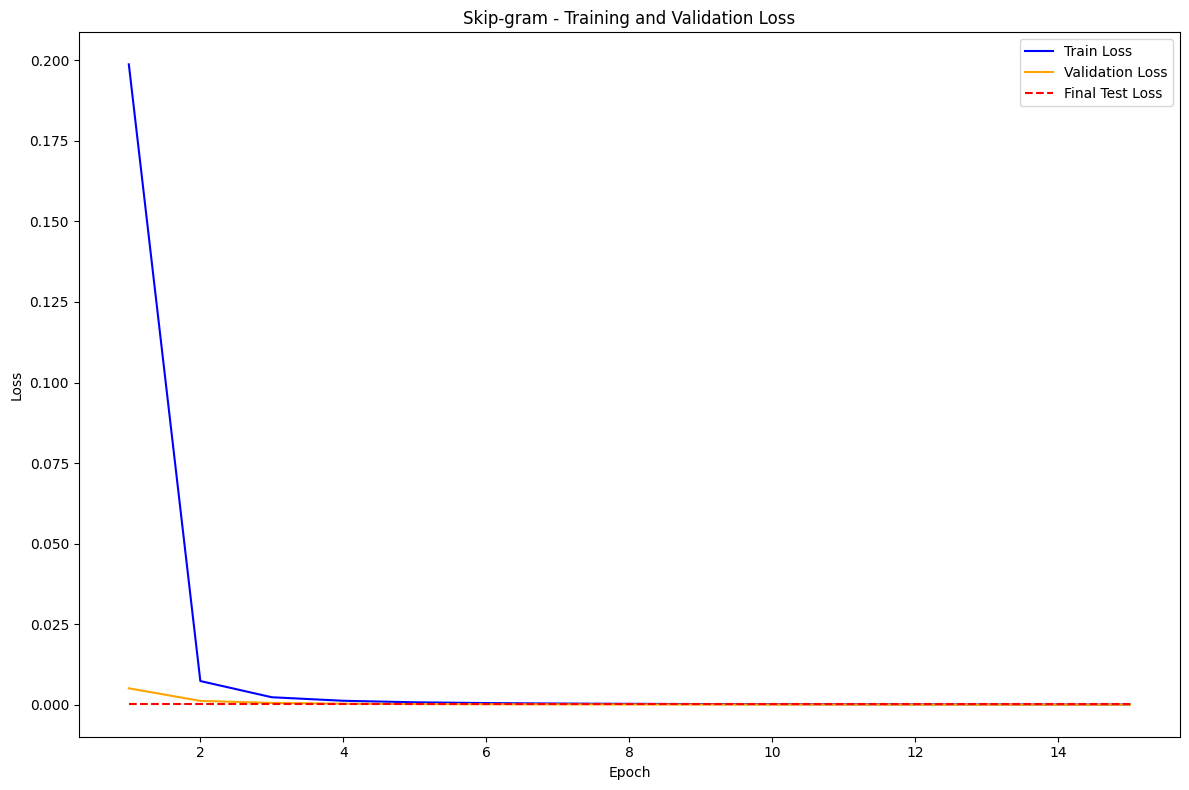

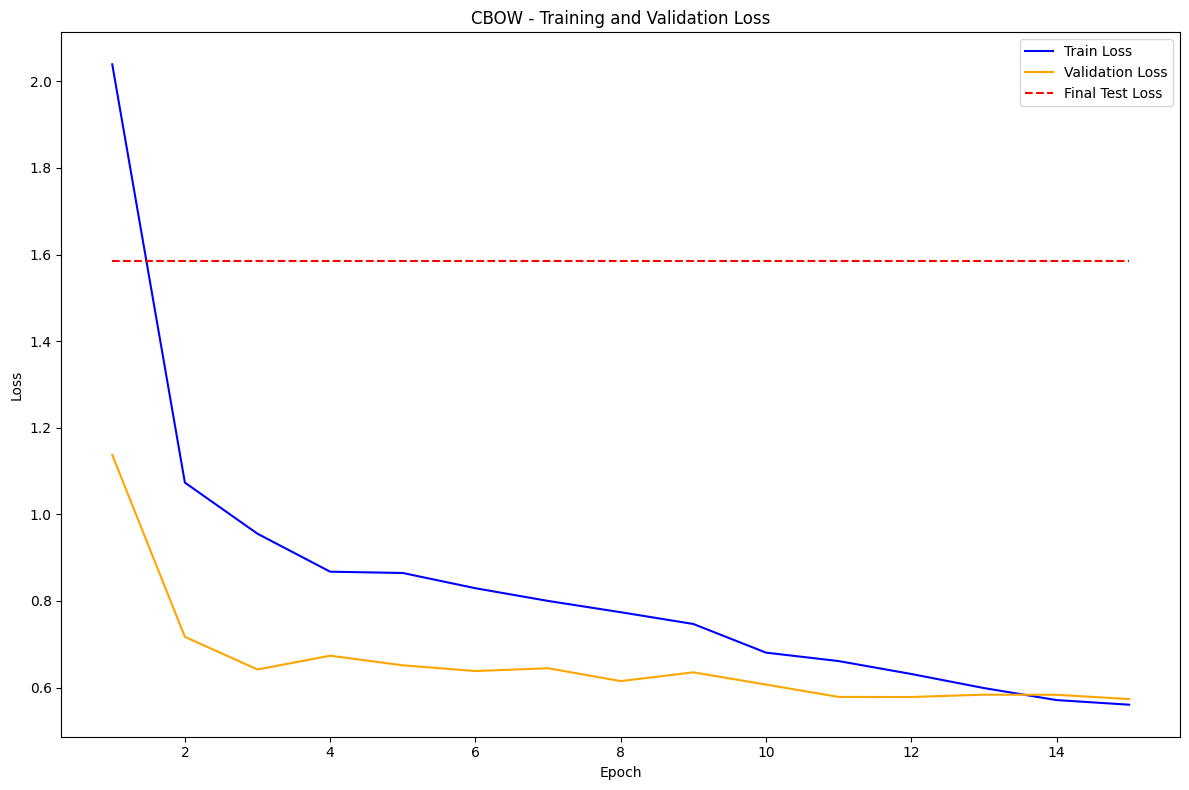

In [ ]:
def build_vocabulary(texts, min_freq=2, unk_token="<UNK>"):
    word_freq = Counter()
    for text in texts:
        tokens = preprocess_text(text)
        word_freq.update(tokens)

    filtered_words = [word for word, count in word_freq.items() if count >= min_freq]
    vocab = [unk_token] + filtered_words

    word2idx = {word: idx for idx, word in enumerate(vocab)}
    idx2word = {idx: word for idx, word in enumerate(vocab)}

    return word2idx, idx2word, word_freq

def create_skipgram_samples(tokens, word2idx, window_size=2):
    samples = []
    unk_idx = word2idx.get("<UNK>", 0)

    for i in range(len(tokens)):
        target_word = tokens[i]
        target_idx = word2idx.get(target_word, unk_idx)
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)

        for j in range(start, end):
            if j != i:
                context_word = tokens[j]
                context_idx = word2idx.get(context_word, unk_idx)
                samples.append((target_idx, context_idx))

    return samples

def create_cbow_samples(tokens, word2idx, window_size=2):
    samples = []
    vocab_size = len(word2idx)
    unk_idx = word2idx.get("<UNK>", 0)

    for i in range(window_size, len(tokens) - window_size):
        context_words = []
        for j in range(-window_size, window_size + 1):
            if j != 0:
                context_words.append(tokens[i + j])

        target_word = tokens[i]
        context_indices = [word2idx.get(word, unk_idx) for word in context_words]
        target_idx = word2idx.get(target_word, unk_idx)
        samples.append((context_indices, target_idx))

    return samples


class SkipGramDataset(Dataset):
    def __init__(self, texts, word2idx, window_size=2):
        self.samples = []
        for text in texts:
            tokens = preprocess_text(text)
            if len(tokens) > window_size * 2:
                samples = create_skipgram_samples(tokens, word2idx, window_size)
                self.samples.extend(samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]

class CBOWDataset(Dataset):
    def __init__(self, texts, word2idx, window_size=2):
        self.samples = []
        for text in texts:
            tokens = preprocess_text(text)
            if len(tokens) > window_size * 2:
                samples = create_cbow_samples(tokens, word2idx, window_size)
                self.samples.extend(samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]

class SkipGramModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super(SkipGramModel, self).__init__()
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.input_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.input_embedding.weight.data.uniform_(-0.1, 0.1)
        self.output_embedding.weight.data.uniform_(-0.1, 0.1)

    def forward(self, target_words, context_words):
        target_embeds = self.input_embedding(target_words)
        context_embeds = self.output_embedding(context_words)
        scores = torch.sum(target_embeds * context_embeds, dim=1)

        return scores

    def get_word_embeddings(self):
        return self.input_embedding.weight.data

class CBOWModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, context_size):
        super(CBOWModel, self).__init__()
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.context_size = context_size
        self.embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.linear = nn.Linear(embedding_dim, vocab_size)
        self.embeddings.weight.data.uniform_(-0.1, 0.1)
        self.linear.weight.data.uniform_(-0.1, 0.1)
        self.linear.bias.data.zero_()

    def forward(self, context_words):
        context_embeds = self.embeddings(context_words)
        avg_embeds = torch.mean(context_embeds, dim=1)
        output = self.linear(avg_embeds)

        return output

    def get_word_embeddings(self):
        return self.embeddings.weight.data


def train_skipgram(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    total_samples = 0

    for batch_idx, (target_words, context_words) in enumerate(dataloader):
        target_words = target_words.to(device)
        context_words = context_words.to(device)
        optimizer.zero_grad()
        scores = model(target_words, context_words)
        labels = torch.ones_like(scores)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(target_words)
        total_samples += len(target_words)

    return total_loss / total_samples

def train_cbow(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    total_samples = 0

    for batch_idx, (context_words, target_words) in enumerate(dataloader):
        context_words = context_words.to(device)
        target_words = target_words.to(device)
        optimizer.zero_grad()
        outputs = model(context_words)
        loss = criterion(outputs, target_words)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(target_words)
        total_samples += len(target_words)

    return total_loss / total_samples

def evaluate_model(model, dataloader, criterion, device, model_type='skipgram'):
    model.eval()
    total_loss = 0
    total_samples = 0
    with torch.no_grad():
        if model_type == 'skipgram':
            for target_words, context_words in dataloader:
                target_words = target_words.to(device)
                context_words = context_words.to(device)
                scores = model(target_words, context_words)
                labels = torch.ones_like(scores)
                loss = criterion(scores, labels)
                total_loss += loss.item() * len(target_words)
                total_samples += len(target_words)

        else:
            for context_words, target_words in dataloader:
                context_words = context_words.to(device)
                target_words = target_words.to(device)
                outputs = model(context_words)
                loss = criterion(outputs, target_words)
                total_loss += loss.item() * len(target_words)
                total_samples += len(target_words)

    return total_loss / total_samples

def skipgram_collate_fn(batch):
    targets = []
    contexts = []
    for target_idx, context_idx in batch:
        targets.append(target_idx)
        contexts.append(context_idx)

    return torch.tensor(targets, dtype=torch.long), torch.tensor(contexts, dtype=torch.long)

def cbow_collate_fn(batch):
    contexts = []
    targets = []
    for context_indices, target_idx in batch:
        contexts.append(context_indices)
        targets.append(target_idx)

    max_len = max(len(ctx) for ctx in contexts)
    padded_contexts = []
    for ctx in contexts:
        if len(ctx) < max_len:
            padded_ctx = ctx + [ctx[0]] * (max_len - len(ctx))
        else:
            padded_ctx = ctx
        padded_contexts.append(padded_ctx)

    return torch.tensor(padded_contexts, dtype=torch.long), torch.tensor(targets, dtype=torch.long)

def plot_training_curves(train_losses, val_losses, test_losses, model_name):
    plt.figure(figsize=(12, 8))
    epochs = range(1, len(train_losses) + 1)
    plt.plot(epochs, train_losses, label='Train Loss', color='blue')
    plt.plot(epochs, val_losses, label='Validation Loss', color='orange')
    plt.plot(epochs, [test_losses[-1]] * len(epochs), label='Final Test Loss', color='red', linestyle='--')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.plot()
    plt.title(f'{model_name} - Training and Validation Loss')
    plt.legend()
    plt.tight_layout()
    plt.show()

def train_word2vec_models(train_texts, val_texts, test_texts, embedding_dim=100,
                          window_size=2, batch_size=64, num_epochs=10, learning_rate=0.01):
    word2idx, idx2word, word_freq = build_vocabulary(train_texts, min_freq=2)
    vocab_size = len(word2idx)
    skipgram_train_dataset = SkipGramDataset(train_texts, word2idx, window_size)
    skipgram_val_dataset = SkipGramDataset(val_texts, word2idx, window_size)
    skipgram_test_dataset = SkipGramDataset(test_texts, word2idx, window_size)
    skipgram_train_loader = DataLoader(skipgram_train_dataset, batch_size=batch_size, shuffle=True, collate_fn=skipgram_collate_fn)
    skipgram_val_loader = DataLoader(skipgram_val_dataset, batch_size=batch_size, collate_fn=skipgram_collate_fn)
    skipgram_test_loader = DataLoader(skipgram_test_dataset, batch_size=batch_size, collate_fn=skipgram_collate_fn)

    cbow_train_dataset = CBOWDataset(train_texts, word2idx, window_size)
    cbow_val_dataset = CBOWDataset(val_texts, word2idx, window_size)
    cbow_test_dataset = CBOWDataset(test_texts, word2idx, window_size)
    cbow_train_loader = DataLoader(cbow_train_dataset, batch_size=batch_size, shuffle=True, collate_fn=cbow_collate_fn)
    cbow_val_loader = DataLoader(cbow_val_dataset, batch_size=batch_size, collate_fn=cbow_collate_fn)
    cbow_test_loader = DataLoader(cbow_test_dataset, batch_size=batch_size, collate_fn=cbow_collate_fn)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    skipgram_model = SkipGramModel(vocab_size, embedding_dim).to(device)
    cbow_model = CBOWModel(vocab_size, embedding_dim, window_size * 2).to(device)

    skipgram_optimizer = optim.Adam(skipgram_model.parameters(), lr=learning_rate)
    cbow_optimizer = optim.Adam(cbow_model.parameters(), lr=learning_rate)

    skipgram_criterion = nn.BCEWithLogitsLoss()
    cbow_criterion = nn.CrossEntropyLoss()

    skipgram_train_losses = []
    skipgram_val_losses = []
    skipgram_test_losses = []

    cbow_train_losses = []
    cbow_val_losses = []
    cbow_test_losses = []

    print("\nTraining Skip-gram: ")
    for epoch in range(num_epochs):
        train_loss = train_skipgram(skipgram_model, skipgram_train_loader, skipgram_optimizer, skipgram_criterion, device)
        val_loss = evaluate_model(skipgram_model, skipgram_val_loader, skipgram_criterion, device, 'skipgram')
        test_loss = evaluate_model(skipgram_model, skipgram_test_loader, skipgram_criterion, device, 'skipgram')

        skipgram_train_losses.append(train_loss)
        skipgram_val_losses.append(val_loss)
        skipgram_test_losses.append(test_loss)

        print(f'Skip-gram Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Test Loss: {test_loss:.4f}')

    print("\nTraining CBOW: ")
    for epoch in range(num_epochs):
        train_loss = train_cbow(cbow_model, cbow_train_loader, cbow_optimizer, cbow_criterion, device)
        val_loss = evaluate_model(cbow_model, cbow_val_loader, cbow_criterion, device, 'cbow')
        test_loss = evaluate_model(cbow_model, cbow_test_loader, cbow_criterion, device, 'cbow')

        cbow_train_losses.append(train_loss)
        cbow_val_losses.append(val_loss)
        cbow_test_losses.append(test_loss)

        print(f'CBOW Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Test Loss: {test_loss:.4f}')

    plot_training_curves(skipgram_train_losses, skipgram_val_losses, skipgram_test_losses, "Skip-gram")
    plot_training_curves(cbow_train_losses, cbow_val_losses, cbow_test_losses, "CBOW")

    return (skipgram_model, cbow_model, word2idx, idx2word, skipgram_train_losses, skipgram_val_losses, skipgram_test_losses,
            cbow_train_losses, cbow_val_losses, cbow_test_losses)

results = train_word2vec_models(
    train_texts=dataset['train']['text'],
    val_texts=dataset['validation']['text'],
    test_texts=dataset['test']['text'],
    embedding_dim=100,
    window_size=2,
    batch_size=4,
    num_epochs=15,
    learning_rate=0.01
)

(skipgram_model, cbow_model, word2idx, idx2word,
 skipgram_train_losses, skipgram_val_losses, skipgram_test_losses,
 cbow_train_losses, cbow_val_losses, cbow_test_losses) = results


## 4. Model Comparison and Analysis

Compare the embeddings learned by the **Skip-gram** and **CBOW** models. For a set of selected target words, retrieve the top-k most similar words using cosine similarity, visualize them in a 2-D t-SNE space, and analyze the qualitative and quantitative differences between the two models' embeddings.

Selected words: ['learning', 'dog', 'human', 'machine', 'data']
Comparison of similar words between Skip-gram and CBOW models

Target word: learning
----------------------------------------
Skip-gram            | Similarity | CBOW                 | Similarity
----------------------------------------------------------------------
and                  | 0.9198     | the                  | 0.9656    
are                  | 0.9193     | understand           | 0.8986    
understand           | 0.9140     | data                 | 0.8504    
data                 | 0.9081     | are                  | 0.8300    
dog                  | 0.8967     | machine              | 0.7914    

Target word: dog
----------------------------------------
Skip-gram            | Similarity | CBOW                 | Similarity
----------------------------------------------------------------------
and                  | 0.9178     | human                | 0.5927    
data                 | 0.9076     | and          

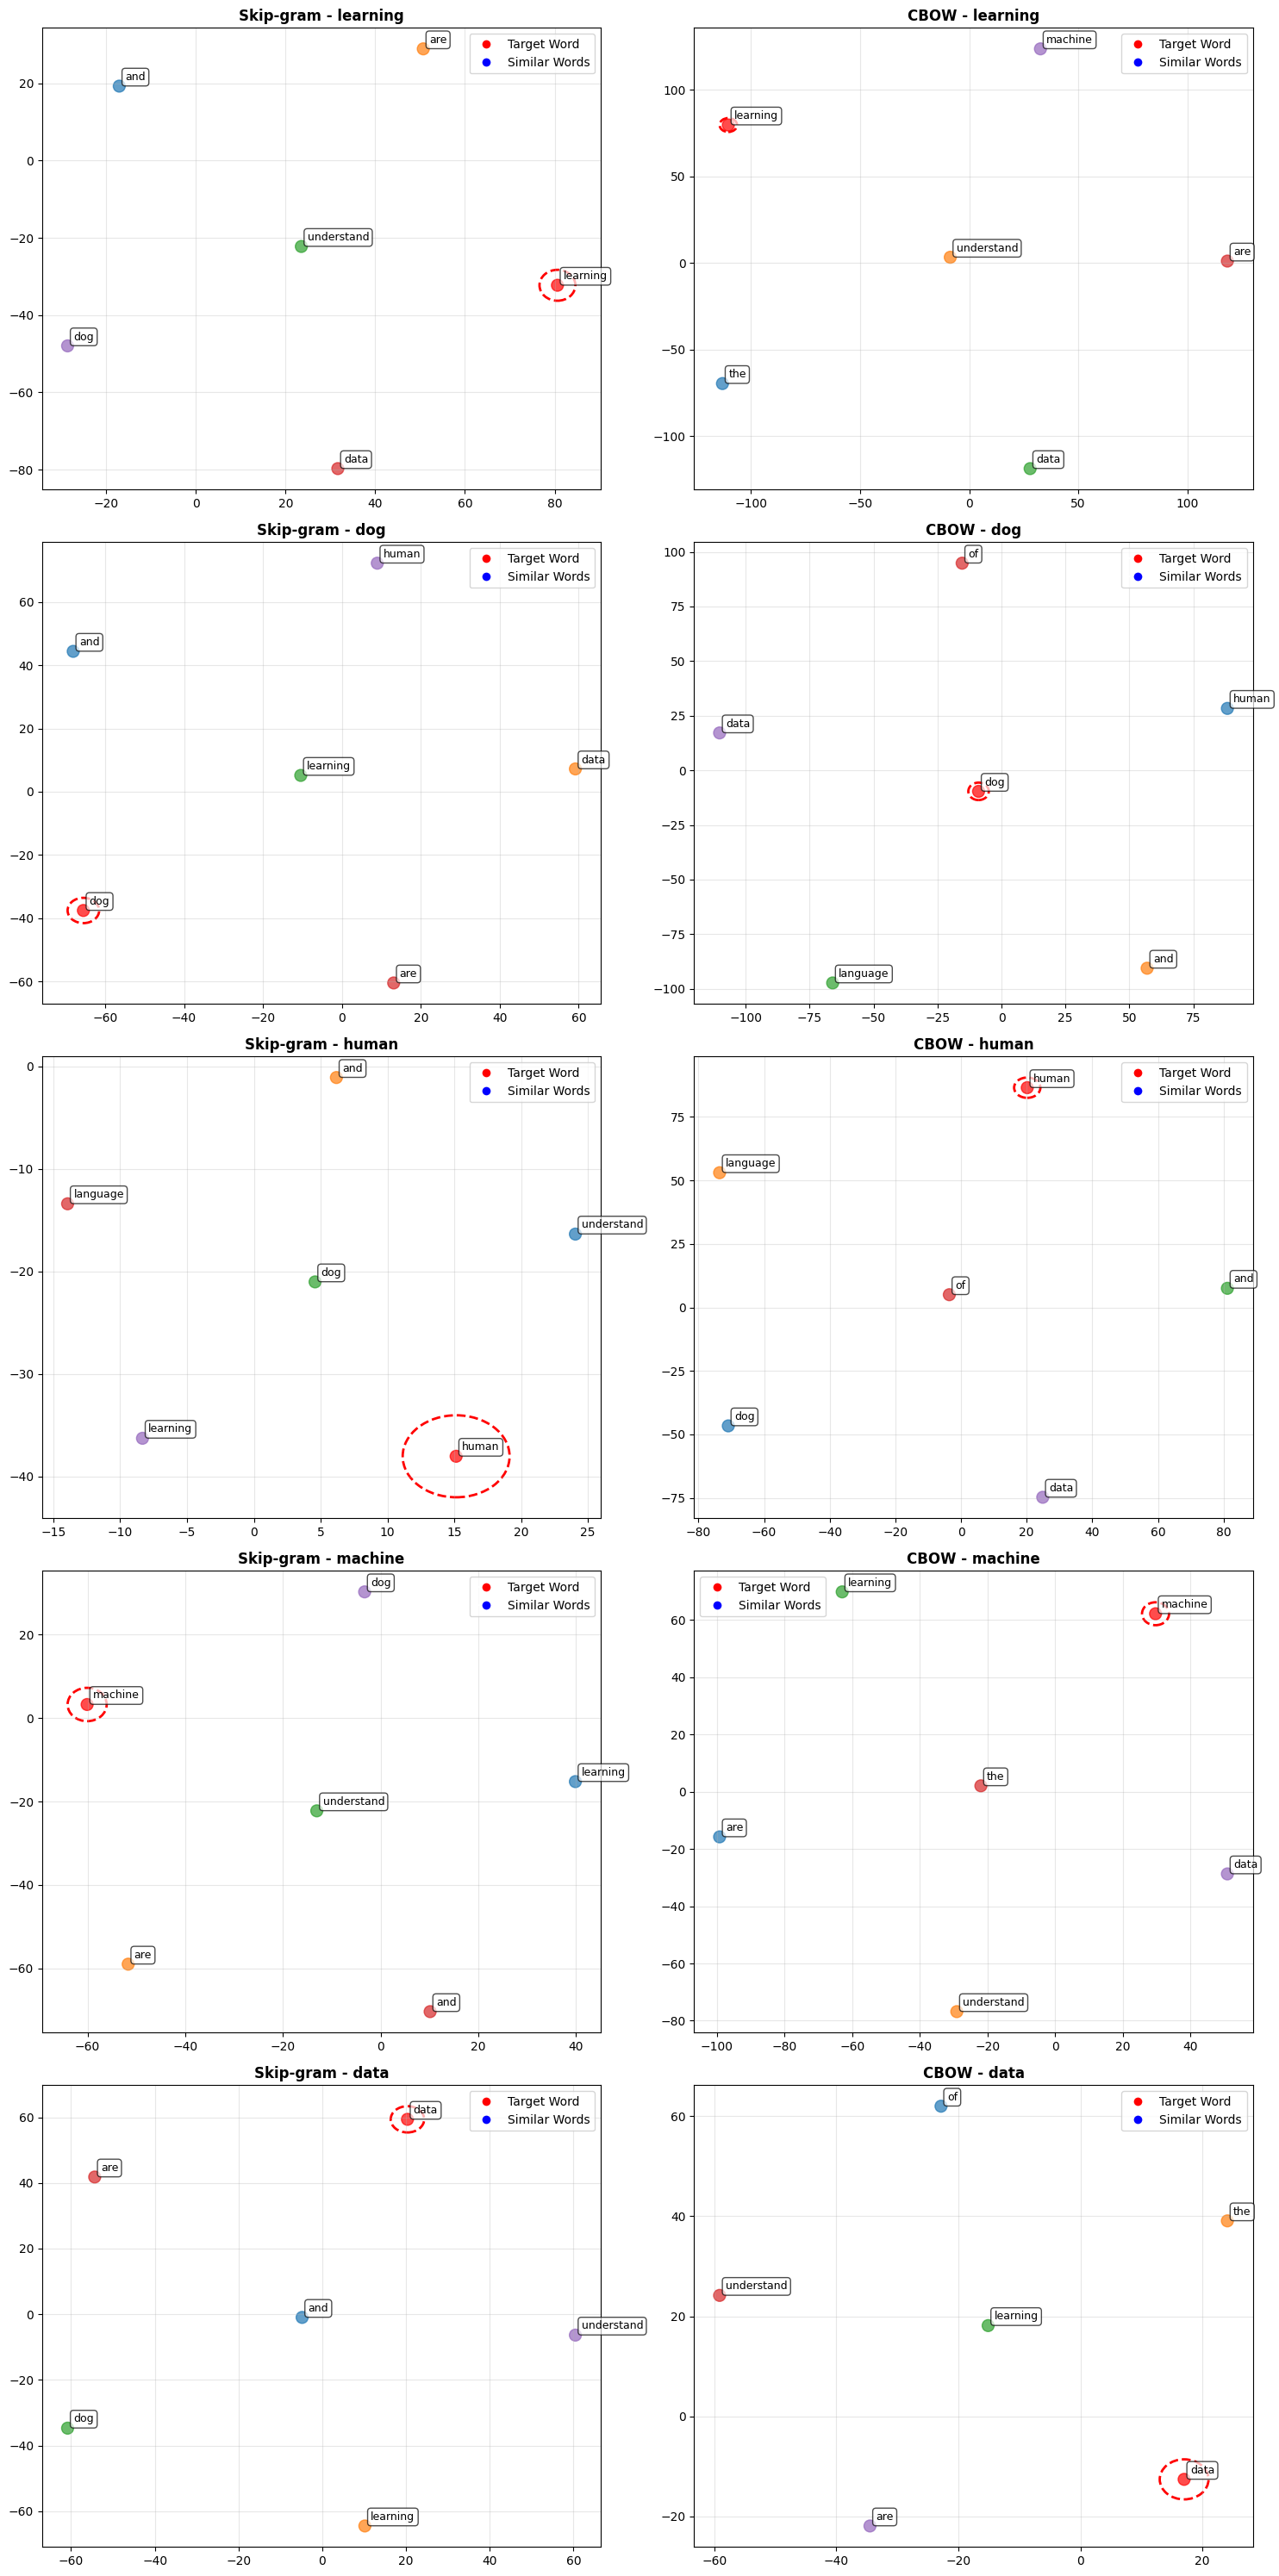


Analyzing the differences between the Skip-gram and CBOW models

Analysis for word 'learning':
 Common words: ['are', 'data', 'understand']
 Skip-gram unique: ['and', 'dog']
 CBOW unique: ['machine', 'the']
 Average Skip-gram similarity: 0.9116
 Average CBOW similarity: 0.8672
 Average difference: 0.0444

Analysis for word 'dog':
 Common words: ['and', 'human', 'data']
 Skip-gram unique: ['are', 'learning']
 CBOW unique: ['language', 'of']
 Average Skip-gram similarity: 0.9010
 Average CBOW similarity: 0.0175
 Average difference: 0.8835

Analysis for word 'human':
 Common words: ['and', 'language', 'dog']
 Skip-gram unique: ['learning', 'understand']
 CBOW unique: ['data', 'of']
 Average Skip-gram similarity: 0.8945
 Average CBOW similarity: 0.1931
 Average difference: 0.7014

Analysis for word 'machine':
 Common words: ['are', 'learning', 'understand']
 Skip-gram unique: ['and', 'dog']
 CBOW unique: ['data', 'the']
 Average Skip-gram similarity: 0.8620
 Average CBOW similarity: 0.776

In [ ]:
selected_words = ['learning', 'dog', 'human', 'machine', 'data']

def get_similar_words_with_embeddings(model, word2idx, idx2word, target_words, top_k=5, model_type='skipgram'):
    device = next(model.parameters()).device

    if model_type == 'skipgram':
        embeddings = model.get_word_embeddings()
    else:
        embeddings = model.get_word_embeddings()

    results = {}

    for target_word in target_words:
        if target_word not in word2idx:
            print(f"The word '{target_word}' does not exist in the vocabulary.")
            continue

        target_idx = word2idx[target_word]
        target_embedding = embeddings[target_idx]
        similarities = []
        for idx, embedding in enumerate(embeddings):
            if idx != target_idx and idx2word[idx] != '<UNK>':
                cos_sim = F.cosine_similarity(target_embedding.unsqueeze(0), embedding.unsqueeze(0))
                similarities.append((idx, cos_sim.item(), embedding))

        similarities.sort(key=lambda x: x[1], reverse=True)
        similar_words_info = []
        for i, (idx, sim, emb) in enumerate(similarities[:top_k]):
            similar_words_info.append({
                'word': idx2word[idx],
                'similarity': sim,
                'embedding': emb.cpu().numpy(),
                'index': idx
            })

        results[target_word] = {
            'target_embedding': target_embedding.cpu().numpy(),
            'target_index': target_idx,
            'similar_words': similar_words_info
        }

    return results

def create_tsne_plot_for_word(model_results, word, model_name, ax):
    if word not in model_results:
        return

    embeddings = []
    labels = []
    colors = []
    target_info = model_results[word]
    embeddings.append(target_info['target_embedding'])
    labels.append(word)
    colors.append('red')

    for i, similar_word_info in enumerate(target_info['similar_words']):
        embeddings.append(similar_word_info['embedding'])
        labels.append(similar_word_info['word'])
        colors.append(f'C{i}')
    embeddings_array = np.array(embeddings)
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(5, len(embeddings)-1))
    embeddings_2d = tsne.fit_transform(embeddings_array)
    scatter = ax.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=colors, s=100, alpha=0.7)
    for i, (x, y) in enumerate(embeddings_2d):
        ax.annotate(labels[i], (x, y), xytext=(5, 5), textcoords='offset points',
                   fontsize=9, fontfamily='DejaVu Sans',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
    target_point = embeddings_2d[0]
    circle = Ellipse((target_point[0], target_point[1]), width=8, height=8,
                    fill=False, color='red', linewidth=2, linestyle='--')
    ax.add_patch(circle)
    ax.set_title(f'{model_name} - {word}', fontsize=12, fontweight='bold', fontfamily='DejaVu Sans')
    ax.grid(True, alpha=0.3)
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=8, label='Target Word'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='Similar Words')
    ]
    ax.legend(handles=legend_elements, loc='best')

def compare_models_tsne(skipgram_results, cbow_results, selected_words):
    fig, axes = plt.subplots(len(selected_words), 2, figsize=(15, 6*len(selected_words)))
    if len(selected_words) == 1:
        axes = axes.reshape(1, -1)
    for i, word in enumerate(selected_words):
        create_tsne_plot_for_word(skipgram_results, word, 'Skip-gram', axes[i, 0])
        create_tsne_plot_for_word(cbow_results, word, 'CBOW', axes[i, 1])

    plt.tight_layout()
    plt.show()

def print_similarity_comparison(skipgram_results, cbow_results, selected_words):
    print("Comparison of similar words between Skip-gram and CBOW models")
    print("=" * 80)
    for word in selected_words:
        print(f"\nTarget word: {word}")
        print("-" * 40)

        if word in skipgram_results and word in cbow_results:
            skipgram_similar = skipgram_results[word]['similar_words']
            cbow_similar = cbow_results[word]['similar_words']

            print(f"{'Skip-gram':<20} | {'Similarity':<10} | {'CBOW':<20} | {'Similarity':<10}")
            print("-" * 70)

            for i in range(5):
                sg_word = skipgram_similar[i]['word'] if i < len(skipgram_similar) else "-"
                sg_sim = f"{skipgram_similar[i]['similarity']:.4f}" if i < len(skipgram_similar) else "-"
                cb_word = cbow_similar[i]['word'] if i < len(cbow_similar) else "-"
                cb_sim = f"{cbow_similar[i]['similarity']:.4f}" if i < len(cbow_similar) else "-"

                print(f"{sg_word:<20} | {sg_sim:<10} | {cb_word:<20} | {cb_sim:<10}")

        elif word not in skipgram_results:
            print(f"The word '{word}' was not found in Skip-gram results.")
        else:
            print(f"The word '{word}' was not found in CBOW results.")

print("Selected words:", selected_words)

skipgram_results = get_similar_words_with_embeddings(skipgram_model, word2idx, idx2word, selected_words, top_k=5, model_type='skipgram')
cbow_results = get_similar_words_with_embeddings(cbow_model, word2idx, idx2word, selected_words, top_k=5, model_type='cbow')
print_similarity_comparison(skipgram_results, cbow_results, selected_words)

print("\n")
compare_models_tsne(skipgram_results, cbow_results, selected_words)

def analyze_model_differences(skipgram_results, cbow_results, selected_words):
    print("\n" + "=" * 80)
    print("Analyzing the differences between the Skip-gram and CBOW models")
    print("=" * 80)

    for word in selected_words:
        if word in skipgram_results and word in cbow_results:
            skipgram_similar = [sw['word'] for sw in skipgram_results[word]['similar_words']]
            cbow_similar = [sw['word'] for sw in cbow_results[word]['similar_words']]
            common_words = set(skipgram_similar) & set(cbow_similar)
            skipgram_unique = set(skipgram_similar) - set(cbow_similar)
            cbow_unique = set(cbow_similar) - set(skipgram_similar)

            print(f"\nAnalysis for word '{word}':")
            print(f" Common words: {list(common_words)}")
            print(f" Skip-gram unique: {list(skipgram_unique)}")
            print(f" CBOW unique: {list(cbow_unique)}")

            sg_avg_sim = np.mean([sw['similarity'] for sw in skipgram_results[word]['similar_words']])
            cb_avg_sim = np.mean([sw['similarity'] for sw in cbow_results[word]['similar_words']])

            print(f" Average Skip-gram similarity: {sg_avg_sim:.4f}")
            print(f" Average CBOW similarity: {cb_avg_sim:.4f}")
            print(f" Average difference: {abs(sg_avg_sim - cb_avg_sim):.4f}")

analyze_model_differences(skipgram_results, cbow_results, selected_words)
